# S3 — Phase 2 : features et Markowitz sur la BVMT (75 titres)

Projet Math en assurance et finance · 5INFINI · données du 02/01/2023 au 03/11/2026.

Ce notebook produit les **10 livrables de la S3** à partir des données de la semaine 2 :

| # | Livrable | Fichier |
|---|---|---|
| 1 | Rendements log des 75 titres | `rendements_log_75.csv` |
| 2 | Rendements log du Tunindex | `tunindex_rendements.csv` |
| 3 | Features (75 × 7) | `features_titres.csv` |
| 4 | Corrélations de Pearson entre features | `correlations_pearson.csv` |
| 5 | Corrélations de Spearman entre features | `correlations_spearman.csv` |
| 6 | Covariance annualisée (75 × 75) | `covariance_annualisee.csv` |
| 7 | Portefeuille de variance minimale | `markowitz_variance_minimale.csv` |
| 8 | Portefeuille de Sharpe maximal (sans vente à découvert) | `markowitz_sharpe_maximal.csv` |
| 9 | Frontière efficiente | `frontiere_efficiente.csv` |
| 10 | Taux sans risque | section 7 et `taux_sans_risque.json` |

**Entrées** (dossier `data/processed/`, construites en S2) : `cotations_long.csv`, `tunindex.csv`, `qualite_par_titre.csv`.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats, optimize
import matplotlib.pyplot as plt

IN = Path("../data/processed") if Path("../data/processed/cotations_long.csv").exists() else Path(".")
OUT = Path("../data/s3") if IN.name == "processed" else Path("out")
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160, "display.max_columns", 12, "display.precision", 4)
JOURS = 252

## 0. Choisir les 75 titres

`qualite_par_titre.csv` contient 85 sociétés. On retire les **10 qui ne sont plus cotées au 03/11/2026** (8 radiées, 2 hors du marché principal) et on **garde les 18 titres peu liquides** que la S2 excluait. On obtient 85 − 10 = 75 titres.

La clé de filtrage est l'ISIN, car les 10 titres retirés n'ont pas de ticker.

In [2]:
q = pd.read_csv(IN / "qualite_par_titre.csv")
non_cotes = q[q.motif_exclusion.fillna("").str.startswith("non coté")]
titres = q.drop(non_cotes.index).copy()
titres["statut"] = np.where(titres.retenu, "liquide (≥ 60 %)", "peu liquide (< 60 %)")
print("Titres retirés :", len(non_cotes)); print(non_cotes[["nom", "isin", "derniere_seance"]].to_string(index=False))
print("\nTitres conservés :", len(titres), "dont", (~titres.retenu).sum(), "peu liquides")
TICKERS = titres.ticker.tolist()

Titres retirés : 10
               nom         isin derniere_seance
             SOPAT TN0007290018      2023-11-03
        GIF-FILTER TN0007130016      2024-11-11
               AMS TN0001500859      2023-09-15
          SERVICOM TN0007340011      2024-04-30
          CEREALIS TN0007640014      2023-02-13
       ELECTROSTAR TN0006650014      2024-09-10
 STE TUN. DU SUCRE TN0006170013      2025-12-31
MAGHREB INTERN PUB TN0007660012      2024-09-10
             SITEX TN0004300307      2025-12-31
             ADWYA TN0007250012      2023-01-05

Titres conservés : 75 dont 18 peu liquides


## 1. Livrable 1 : rendements log des 75 titres

Formule : r_t = ln(clôture_t / cours de référence_t).

Le **cours de référence** est publié par la Bourse : il vaut la clôture de la veille, sauf les jours d'opération sur titres (dividende, attribution gratuite, division), où la Bourse l'ajuste. Ce rendement est donc identique à ln(P*_t / P*_{t−1}) calculé sur les prix ajustés, comme l'exige le cahier.

**Jour sans échange.** Le cours de clôture reste le cours de référence, donc le rendement vaut **0**. On garde ce 0 au lieu d'une case vide : c'est la variation réellement observable, et toutes les séries restent alignées sur le même calendrier. Le prix à payer est une volatilité sous-estimée pour les titres peu échangés (voir section 6).

La première séance (02/01/2023) n'a pas de rendement : 960 séances de cours donnent 959 lignes.

In [3]:
c = pd.read_csv(IN / "cotations_long.csv", parse_dates=["date"])
c = c[c["isin"].isin(titres["isin"])]
R = c.pivot(index="date", columns="ticker", values="rendement_log")[TICKERS].iloc[1:]
print("Forme :", R.shape, "| valeurs manquantes :", int(R.isna().sum().sum()))
print("Période :", R.index.min().date(), "→", R.index.max().date())
R.to_csv(OUT / "rendements_log_75.csv")
R.iloc[:3, :6]

Forme : (959, 75) | valeurs manquantes : 0
Période : 2023-01-03 → 2026-11-03


ticker,SFBT,BIAT,SAH,TJARI,BNA,CC
date,,,,,,
2023-01-03,-0.0083,0.0045,-0.0101,-0.0108,0.0000,0.0000
2023-01-04,-0.0099,-0.0006,-0.0102,0.0235,-0.0092,0.0052
2023-01-05,-0.0054,0.0006,-0.0023,-0.0021,0.0081,0.0000


## 2. Livrable 2 : rendements log du Tunindex

Mêmes dates que le livrable 1, car le bêta compare les deux séries jour par jour.

In [4]:
t = pd.read_csv(IN / "tunindex.csv", parse_dates=["date"], index_col="date")
M = t["rendement_log"].iloc[1:].rename("TUNINDEX")
assert M.index.equals(R.index), "les dates ne correspondent pas"
M.to_frame().to_csv(OUT / "tunindex_rendements.csv")
print("Dates identiques au livrable 1 :", M.index.equals(R.index))
print(f"Tunindex : rendement annualisé {M.mean()*JOURS:.1%}, volatilité annualisée {M.std()*np.sqrt(JOURS):.1%}")

Dates identiques au livrable 1 : True
Tunindex : rendement annualisé 22.0%, volatilité annualisée 7.6%


## 3. Livrable 3 : les 7 features par titre

Une valeur par titre sur toute la période :

| Feature | Calcul |
|---|---|
| Rendement annualisé | moyenne des r_t × 252 |
| Volatilité annualisée | écart-type des r_t × √252 |
| Skewness | asymétrie (estimateur corrigé du biais) |
| Kurtosis | kurtosis **en excès** (0 pour une loi normale), corrigé du biais |
| VaR 95 % | quantile à 5 % des r_t journaliers (historique, nombre négatif) |
| CVaR 95 % | moyenne des r_t inférieurs ou égaux à la VaR (nombre négatif) |
| Bêta | Cov(r_i, r_M) / Var(r_M) |

La VaR et la CVaR restent **journalières**, comme dans la littérature et dans le guide : ce sont des pertes sur un jour.

In [5]:
def features(R, M):
    var95 = R.quantile(0.05)
    cvar95 = R.apply(lambda s: s[s <= s.quantile(0.05)].mean())
    beta = R.apply(lambda s: np.cov(s, M, ddof=1)[0, 1] / M.var(ddof=1))
    return pd.DataFrame({
        "rendement_annualise": R.mean() * JOURS,
        "volatilite_annualisee": R.std(ddof=1) * np.sqrt(JOURS),
        "skewness": R.apply(lambda s: stats.skew(s, bias=False)),
        "kurtosis": R.apply(lambda s: stats.kurtosis(s, fisher=True, bias=False)),
        "var_95": var95, "cvar_95": cvar95, "beta": beta})

F = features(R, M)
F.index.name = "ticker"
F.to_csv(OUT / "features_titres.csv")
print(F.describe().loc[["mean", "min", "50%", "max"]].round(3))
F.loc[["SFBT", "BIAT", "TJARI", "PLTU"]].round(4)

      rendement_annualise  volatilite_annualisee  skewness  kurtosis  var_95  cvar_95   beta
mean                0.153                  0.260     0.471     6.043  -0.026   -0.035  0.432
min                -0.391                  0.048    -0.777    -0.947  -0.045   -0.051 -0.190
50%                 0.172                  0.243     0.263     2.834  -0.024   -0.038  0.395
max                 0.594                  0.412    11.728   164.309   0.000   -0.000  1.556


,rendement_annualise,volatilite_annualisee,skewness,kurtosis,var_95,cvar_95,beta
ticker,,,,,,,
SFBT,0.0884,0.1679,0.9659,4.8662,-0.0146,-0.0214,0.8230
BIAT,0.2553,0.1585,0.5369,6.3629,-0.0119,-0.0214,1.4086
TJARI,0.3213,0.1974,0.5379,3.9622,-0.0160,-0.0256,1.5339
PLTU,0.0477,0.0481,11.7281,164.3095,0.0000,-0.0000,-0.0048


**Lecture.** Trois titres ont une VaR 95 % égale à 0 : SIMPA, BHASS et PLTU. Plus de 95 % de leurs rendements journaliers sont nuls, donc le quantile à 5 % vaut 0. Ce n'est pas une erreur, mais c'est le symptôme le plus net de l'illiquidité.

Le marché a fortement monté sur la période (Tunindex +13,7 % en 2024, +35,1 % en 2025, +38,8 % sur 2026 au 03/11). La plupart des titres ont donc un rendement annualisé élevé. Les titres peu liquides se repèrent à leur volatilité très faible (PLTU, SIMPA) et à leur kurtosis très élevé : leur prix reste immobile pendant des semaines puis saute d'un coup.

## 4. Livrables 4 et 5 : corrélations entre features (Pearson et Spearman)

Corrélations entre les 7 colonnes du livrable 3, calculées sur les 75 titres.

- **Pearson** mesure la relation **linéaire**. Il est sensible aux valeurs extrêmes.
- **Spearman** est la corrélation de Pearson calculée sur les **rangs**. Il mesure une relation **monotone** et résiste aux valeurs extrêmes.

In [6]:
P = F.corr(method="pearson"); S_ = F.corr(method="spearman")
P.to_csv(OUT / "correlations_pearson.csv"); S_.to_csv(OUT / "correlations_spearman.csv")
print("Pearson"); print(P.round(2)); print("\nSpearman"); print(S_.round(2))

Pearson
                       rendement_annualise  volatilite_annualisee  skewness  kurtosis  var_95  cvar_95  beta
rendement_annualise                   1.00                  -0.24      0.09     -0.06    0.36     0.22  0.43
volatilite_annualisee                -0.24                   1.00     -0.49     -0.50   -0.91    -0.85 -0.31
skewness                              0.09                  -0.49      1.00      0.92    0.47     0.59  0.02
kurtosis                             -0.06                  -0.50      0.92      1.00    0.44     0.56 -0.14
var_95                                0.36                  -0.91      0.47      0.44    1.00     0.89  0.43
cvar_95                               0.22                  -0.85      0.59      0.56    0.89     1.00  0.32
beta                                  0.43                  -0.31      0.02     -0.14    0.43     0.32  1.00

Spearman
                       rendement_annualise  volatilite_annualisee  skewness  kurtosis  var_95  cvar_95  beta
r

In [7]:
paires = []
for i, a in enumerate(F.columns):
    for b in F.columns[i+1:]:
        paires.append((a, b, P.loc[a, b], S_.loc[a, b]))
paires = pd.DataFrame(paires, columns=["feature_1", "feature_2", "pearson", "spearman"])
paires["ecart"] = paires.pearson - paires.spearman
print("Paires les plus corrélées (|Spearman| ≥ 0,7) :")
print(paires[paires.spearman.abs() >= 0.7].sort_values("spearman", key=abs, ascending=False).round(2).to_string(index=False))
print("\nPlus gros écarts Pearson − Spearman (effet des valeurs extrêmes) :")
print(paires.reindex(paires.ecart.abs().sort_values(ascending=False).index).head(4).round(2).to_string(index=False))

Paires les plus corrélées (|Spearman| ≥ 0,7) :
            feature_1 feature_2  pearson  spearman  ecart
               var_95   cvar_95     0.89      0.95  -0.05
volatilite_annualisee    var_95    -0.91     -0.93   0.02
             skewness   cvar_95     0.59      0.89  -0.31
volatilite_annualisee   cvar_95    -0.85     -0.88   0.04
volatilite_annualisee  kurtosis    -0.50     -0.88   0.39
             skewness    var_95     0.47      0.84  -0.37
             kurtosis    var_95     0.44      0.80  -0.36
volatilite_annualisee  skewness    -0.49     -0.73   0.24

Plus gros écarts Pearson − Spearman (effet des valeurs extrêmes) :
            feature_1 feature_2  pearson  spearman  ecart
             skewness      beta     0.02      0.57  -0.55
  rendement_annualise  skewness     0.09      0.50  -0.42
volatilite_annualisee  kurtosis    -0.50     -0.88   0.39
             skewness    var_95     0.47      0.84  -0.37


**Lecture pour le rapport.**
- Volatilité, VaR et CVaR sont fortement corrélées entre elles : sur des rendements proches de la normale, VaR ≈ −1,65 σ et CVaR ≈ −2,06 σ (en journalier). Ces trois features mesurent presque la même chose. Les garder toutes les trois dans k-means revient à **surpondérer le risque** dans la distance euclidienne. Pour la S4 : en garder une, ou passer par une ACP.
- Les écarts entre Pearson et Spearman viennent des valeurs extrêmes, en particulier des titres peu liquides au kurtosis très élevé.

## 5. Livrable 6 : covariance annualisée (75 × 75)

Σ = covariance des rendements journaliers × 252. La diagonale est la variance (volatilité²). Elle se calcule à partir des rendements jour par jour, pas à partir du tableau des features.

**Règle d'or.** Le rendement attendu (μ) et Σ sont tous les deux annualisés, sinon le risque serait sous-estimé d'un facteur 252.

In [8]:
Sigma = R.cov(ddof=1) * JOURS
Sigma.to_csv(OUT / "covariance_annualisee.csv")
mu = F["rendement_annualise"]
vp = np.linalg.eigvalsh(Sigma.values)
print("Symétrique :", np.allclose(Sigma, Sigma.T), "| définie positive :", vp.min() > 0)
print(f"Valeurs propres : min {vp.min():.5f}, max {vp.max():.3f}, conditionnement {vp.max()/vp.min():.0f}")
print("Contrôle diagonale = volatilité² :", np.allclose(np.sqrt(np.diag(Sigma)), F.volatilite_annualisee))
Sigma.iloc[:4, :4].round(4)

Symétrique : True | définie positive : True
Valeurs propres : min 0.00221, max 0.216, conditionnement 98
Contrôle diagonale = volatilité² : True


ticker,SFBT,BIAT,SAH,TJARI
ticker,,,,
SFBT,0.0282,0.0023,0.0023,0.0023
BIAT,0.0023,0.0251,0.0038,0.0099
SAH,0.0023,0.0038,0.0257,0.0052
TJARI,0.0023,0.0099,0.0052,0.0390


## 6. Livrable 10 : le taux sans risque

**Choix : TMM d'octobre 2026 = 7,00 % par an**, soit le dernier taux publié avant la date d'extraction (03/11/2026).

- La BCT indique que le TMM est resté à 7 % en octobre 2026, pour le troisième mois consécutif (La Presse, 02/11/2026 ; L'Économiste Maghrébin, 02/11/2026).
- C'est aussi le niveau du taux directeur de la BCT, inchangé à 7 % depuis le 07/01/2026 et confirmé le 07/10/2026.
- Le TMM est le taux de référence des placements monétaires en dinars. C'est le choix standard en Tunisie, et le même ordre de grandeur que les BTA courts.

**Conversion.** Nos rendements sont des log-rendements annualisés. Pour comparer des grandeurs de même nature, on convertit le taux simple en taux continu : r_f = ln(1,07) = **6,77 %**. Avec 7 % pris directement, les Sharpe baissent d'environ 0,01 à 0,02, sans changer les conclusions.

In [9]:
RF_SIMPLE = 0.07
RF = float(np.log(1 + RF_SIMPLE))
json.dump({"taux_simple_annuel": RF_SIMPLE, "taux_continu_annuel_utilise": round(RF, 6),
           "reference": "TMM octobre 2026 (BCT), égal au taux directeur BCT 7,00 %",
           "sources": ["https://www.lapresse.tn/2026/11/02/bct-le-tmm-demeure-stable-au-niveau-de-7-en-octobre-2026/",
                       "https://www.leconomistemaghrebin.com/2026/11/02/le-tmm-maintenu-a-7-en-octobre-2026/",
                       "https://businessnews.com.tn/2026/10/07/la-bct-maintient-son-taux-directeur-a-7-2/1421819/"],
           "date_reference": "2026-11-03"}, open(OUT / "taux_sans_risque.json", "w"), ensure_ascii=False, indent=2)
print(f"r_f utilisé = ln(1,07) = {RF:.4%}")
print("Titres dont le rendement annualisé dépasse r_f :", int((mu > RF).sum()), "sur", len(mu))

r_f utilisé = ln(1,07) = 6.7659%
Titres dont le rendement annualisé dépasse r_f : 51 sur 75


## 7. Markowitz

Pour des poids w (somme 1) : rendement μᵀw, variance wᵀΣw, Sharpe (μᵀw − r_f)/√(wᵀΣw).

### 7.1 Livrable 7 : variance minimale

**Forme fermée demandée par le cahier** : w = Σ⁻¹𝟙 / (𝟙ᵀΣ⁻¹𝟙). Elle autorise la vente à découvert (poids négatifs possibles). On calcule aussi la version **sans vente à découvert** (w ≥ 0, optimisation quadratique), plus réaliste à la BVMT où la vente à découvert n'est pas pratiquée. Le fichier contient les deux colonnes.

In [10]:
def perf(w, mu=mu, S=Sigma):
    r = float(w @ mu); v = float(np.sqrt(w @ S.values @ w))
    return r, v, (r - RF) / v

def min_var_ferme(S):
    x = np.linalg.solve(S.values, np.ones(len(S)))
    return x / x.sum()

def qp(S, mu=None, cible=None):
    """min wᵀΣw  s.c. Σw = 1, w ≥ 0 (et μᵀw = cible si donnée) — SLSQP avec gradient exact."""
    n = len(S); A = S.values
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1, "jac": lambda w: np.ones(n)}]
    if cible is not None:
        cons.append({"type": "eq", "fun": lambda w: w @ mu.values - cible, "jac": lambda w: mu.values})
    res = optimize.minimize(lambda w: w @ A @ w, np.full(n, 1/n), jac=lambda w: 2 * A @ w,
                            bounds=[(0, 1)] * n, constraints=cons, method="SLSQP",
                            options={"ftol": 1e-14, "maxiter": 1000})
    assert res.success, res.message
    w = np.clip(res.x, 0, None); return w / w.sum()

w_gmv = min_var_ferme(Sigma)
w_gmv_lo = qp(Sigma)
gmv = pd.DataFrame({"poids_forme_fermee": w_gmv, "poids_sans_vente_a_decouvert": w_gmv_lo}, index=Sigma.index)
gmv.index.name = "ticker"
gmv.to_csv(OUT / "markowitz_variance_minimale.csv")
for nom, w in [("forme fermée", w_gmv), ("sans vente à découvert", w_gmv_lo)]:
    r, v, s = perf(w)
    print(f"{nom:24s} rendement {r:6.1%}  volatilité {v:5.1%}  Sharpe {s:5.2f}  "
          f"somme {w.sum():.4f}  poids<0 : {(w < -1e-9).sum()}  titres > 1 % : {(w > 0.01).sum()}")
gmv.sort_values("poids_forme_fermee", ascending=False).head(8).round(3)

forme fermée             rendement   8.9%  volatilité  2.9%  Sharpe  0.74  somme 1.0000  poids<0 : 9  titres > 1 % : 21
sans vente à découvert   rendement   9.0%  volatilité  2.9%  Sharpe  0.77  somme 1.0000  poids<0 : 0  titres > 1 % : 21


,poids_forme_fermee,poids_sans_vente_a_decouvert
ticker,,
PLTU,0.368,0.369
SIMPA,0.145,0.143
BHASS,0.034,0.033
WIFAK,0.027,0.027
AL,0.019,0.018
SFBT,0.018,0.016
HL,0.017,0.017
SAH,0.016,0.015


**Lecture : c'est exactement le piège de l'illiquidité.** Les plus gros poids vont à des titres comme PLTU ou SIMPA, qui ne sont presque jamais échangés (4 % et 12 % des séances) et dont la volatilité est donc artificiellement très basse. Le portefeuille paraît extrêmement peu risqué, mais on ne pourrait pas l'acheter en pratique. Ce résultat justifie la comparaison avec les 57 titres liquides (section 8).

### 7.2 Livrable 8 : Sharpe maximal sans vente à découvert

On résout un programme quadratique **exact**, sans simulation aléatoire. Il passe par le changement de variable de Cornuejols-Tütüncü :

min yᵀΣy  sous (μ − r_f)ᵀy = 1, y ≥ 0, puis w = y / Σy.

Le problème est convexe, donc la solution trouvée est l'optimum global.

In [11]:
def max_sharpe(S, mu, rf):
    n = len(S); A = S.values; e = (mu - rf).values
    i0 = np.argmax(e / np.sqrt(np.diag(A)))
    y0 = np.zeros(n); y0[i0] = 1 / e[i0]
    res = optimize.minimize(lambda y: y @ A @ y, y0, jac=lambda y: 2 * A @ y, bounds=[(0, None)] * n,
                            constraints=[{"type": "eq", "fun": lambda y: y @ e - 1, "jac": lambda y: e}],
                            method="SLSQP", options={"ftol": 1e-15, "maxiter": 2000})
    assert res.success, res.message
    y = np.clip(res.x, 0, None); return y / y.sum()

w_ms = max_sharpe(Sigma, mu, RF)
ms = pd.DataFrame({"poids": w_ms}, index=Sigma.index); ms.index.name = "ticker"
ms.to_csv(OUT / "markowitz_sharpe_maximal.csv")
r, v, s = perf(w_ms)
print(f"Sharpe maximal : rendement {r:.1%}, volatilité {v:.1%}, Sharpe {s:.2f}, somme {w_ms.sum():.4f}, "
      f"titres avec un poids > 0,1 % : {(w_ms > 1e-3).sum()}")
# contrôle : aucun portefeuille aléatoire ne doit faire mieux
rng = np.random.default_rng(0); W = rng.dirichlet(np.ones(len(mu)) * 0.3, 20000)
sr = (W @ mu.values - RF) / np.sqrt(np.einsum("ij,jk,ik->i", W, Sigma.values, W))
print(f"Contrôle : meilleur Sharpe parmi 20 000 portefeuilles aléatoires = {sr.max():.2f} (< {s:.2f})")
ms[ms.poids > 1e-3].sort_values("poids", ascending=False).round(3)

Sharpe maximal : rendement 36.9%, volatilité 6.1%, Sharpe 4.93, somme 1.0000, titres avec un poids > 0,1 % : 33


Contrôle : meilleur Sharpe parmi 20 000 portefeuilles aléatoires = 3.22 (< 4.93)


,poids
ticker,
AB,0.103
AL,0.076
MGR,0.070
TINV,0.068
TJL,0.059
ATL,0.057
TLS,0.049
HL,0.047
SPDIT,0.041


**Lecture.** Comme le prévoyait le guide, l'optimisation **concentre** le capital sur quelques titres et met tous les autres à 0. C'est le défaut de Markowitz que souligne la littérature (DeMiguel et al., 2009) : la solution dépend surtout des rendements moyens estimés, très bruités. Sur une période où le marché a pris plus de 35 % par an, ces rendements ne se reproduiront pas forcément. La comparaison hors échantillon de la Phase 3 servira à le vérifier.

### 7.2 bis Un Sharpe de 4,9 est-il crédible ? Non, et c'est un résultat à présenter

Nous retrouvons un Sharpe maximal du même ordre que celui de l'article (3,2 à 4,9), que nous avons critiqué. C'est cohérent avec notre critique : ce chiffre est **en échantillon** et gonflé par trois effets, que la cellule suivante mesure :

1. **Marché très haussier** : le Tunindex a pris environ 22 % par an en log sur la période (+30 % et +33 % en log en 2025 et 2026). Les rendements moyens estimés ne sont pas des prévisions.
2. **Optimisation sur les mêmes données** : l'optimiseur choisit les titres qui ont le plus monté *a posteriori*.
3. **Volatilité sous-estimée par les prix qui s'ajustent avec retard** : les rendements journaliers sont autocorrélés, si bien que la volatilité journalière × √252 sous-estime le risque. Sur des rendements hebdomadaires, la volatilité est plus élevée et le Sharpe baisse.

Ces Sharpe ne doivent donc pas être lus comme une performance réalisable. La Phase 3 (test hors échantillon) servira à le montrer.

In [12]:
Mw = M.resample("W-FRI").sum(); Rw = R.resample("W-FRI").sum()
print(f"Autocorrélation d'ordre 1 du Tunindex : {M.autocorr(1):.2f} (0 attendu pour un marché sans friction)")
print(f"Volatilité du Tunindex : {M.std()*np.sqrt(JOURS):.1%} en journalier × √252, {Mw.std()*np.sqrt(52):.1%} en hebdomadaire × √52")
ratio = (Rw.std()*np.sqrt(52)) / (R.std()*np.sqrt(JOURS))
print(f"Volatilité hebdomadaire / journalière, médiane sur les 75 titres : {ratio.median():.2f}")
Sw = Rw.cov() * 52
print(f"Sharpe du portefeuille de Sharpe maximal : {perf(w_ms)[2]:.2f} (covariance journalière), "
      f"{(w_ms @ mu - RF)/np.sqrt(w_ms @ Sw.values @ w_ms):.2f} (covariance hebdomadaire)")
print("Rendement log du Tunindex par année :", M.groupby(M.index.year).sum().round(3).to_dict())

Autocorrélation d'ordre 1 du Tunindex : 0.29 (0 attendu pour un marché sans friction)
Volatilité du Tunindex : 7.6% en journalier × √252, 9.9% en hebdomadaire × √52
Volatilité hebdomadaire / journalière, médiane sur les 75 titres : 1.07
Sharpe du portefeuille de Sharpe maximal : 4.93 (covariance journalière), 3.70 (covariance hebdomadaire)
Rendement log du Tunindex par année : {2023: 0.078, 2024: 0.129, 2025: 0.301, 2026: 0.328}


### 7.3 Livrable 9 : frontière efficiente (sans vente à découvert)

Pour chaque rendement visé m, entre celui du portefeuille de variance minimale et le plus grand rendement individuel, on résout :

min wᵀΣw  sous Σw = 1, μᵀw = m, w ≥ 0.

Chaque ligne du fichier est un portefeuille optimal : rendement, volatilité, Sharpe, puis les 75 poids.

In [13]:
r_min = float(w_gmv_lo @ mu); r_max = float(mu.max())
cibles = np.linspace(r_min, r_max, 40)
lignes = []
for m in cibles:
    w = qp(Sigma, mu, cible=m) if m > r_min + 1e-9 else w_gmv_lo
    r, v, s = perf(w)
    lignes.append({"rendement": r, "volatilite": v, "sharpe": s, **dict(zip(Sigma.index, w))})
front = pd.DataFrame(lignes)
# on ajoute le portefeuille de Sharpe maximal, qui est sur la frontière
r, v, s = perf(w_ms)
front = pd.concat([front, pd.DataFrame([{"rendement": r, "volatilite": v, "sharpe": s, **dict(zip(Sigma.index, w_ms))}])])
front = front.sort_values("rendement").reset_index(drop=True)
front.insert(0, "portefeuille", "")
front.loc[front.volatilite.idxmin(), "portefeuille"] = "variance minimale"
front.loc[front.sharpe.idxmax(), "portefeuille"] = "Sharpe maximal"
front.to_csv(OUT / "frontiere_efficiente.csv", index=False)
print(front.shape); front[["portefeuille", "rendement", "volatilite", "sharpe"]].iloc[::5].round(3)

(41, 79)


,portefeuille,rendement,volatilite,sharpe
0,variance minimale,0.090,0.029,0.765
5,,0.154,0.031,2.812
10,,0.219,0.037,4.110
15,,0.284,0.046,4.698
20,,0.349,0.057,4.909
25,,0.400,0.068,4.865
30,,0.465,0.093,4.292
35,,0.530,0.166,2.785
40,,0.594,0.321,1.640


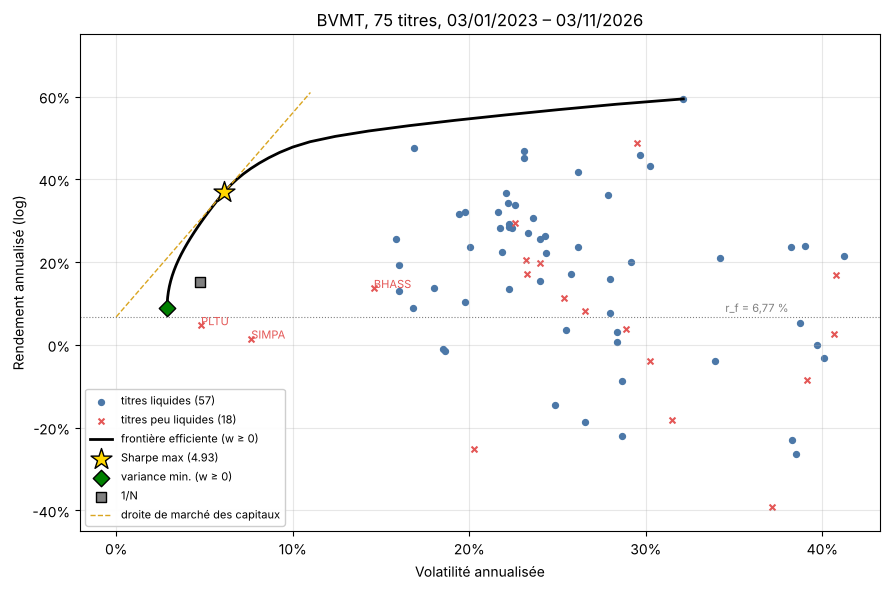

In [14]:
fig, ax = plt.subplots(figsize=(9, 6))
liq = titres.set_index("ticker").retenu.reindex(F.index)
ax.scatter(F.volatilite_annualisee[liq], mu[liq], s=18, c="#4C78A8", label="titres liquides (57)")
ax.scatter(F.volatilite_annualisee[~liq], mu[~liq], s=18, c="#E45756", marker="x", label="titres peu liquides (18)")
ax.plot(front.volatilite, front.rendement, c="black", lw=2, label="frontière efficiente (w ≥ 0)")
r, v, s = perf(w_ms); ax.scatter(v, r, marker="*", s=250, c="gold", ec="k", zorder=5, label=f"Sharpe max ({s:.2f})")
r, v, s = perf(w_gmv_lo); ax.scatter(v, r, marker="D", s=70, c="green", ec="k", zorder=5, label="variance min. (w ≥ 0)")
r, v, s = perf(np.full(len(mu), 1/len(mu))); ax.scatter(v, r, marker="s", s=60, c="gray", ec="k", zorder=5, label="1/N")
x = np.linspace(0, 0.11, 10); ax.plot(x, RF + perf(w_ms)[2] * x, ls="--", c="goldenrod", lw=1, label="droite de marché des capitaux")
ax.axhline(RF, c="gray", lw=0.8, ls=":"); ax.text(0.345, RF + 0.012, "r_f = 6,77 %", color="gray", fontsize=8)
for tk in ["PLTU", "SIMPA", "BHASS"]:
    ax.annotate(tk, (F.loc[tk, "volatilite_annualisee"], mu[tk]), fontsize=8, color="#E45756")
ax.set_xlabel("Volatilité annualisée"); ax.set_ylabel("Rendement annualisé (log)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("BVMT, 75 titres, 03/01/2023 – 03/11/2026"); ax.set_ylim(-0.45, 0.75); ax.legend(fontsize=8, loc="lower left", framealpha=0.95); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(OUT / "frontiere_efficiente.png", dpi=150); plt.show()

## 8. Analyse de sensibilité : 75 titres contre 57 titres liquides

Le guide recommande de refaire Markowitz sur les 57 titres liquides pour mesurer l'effet des titres peu échangés. On réutilise exactement les mêmes fonctions.

In [15]:
liquides = titres[titres.retenu].ticker.tolist()
S57, mu57 = Sigma.loc[liquides, liquides], mu[liquides]
res = []
for univ, S, m in [("75 titres", Sigma, mu), ("57 liquides", S57, mu57)]:
    for nom, w in [("variance min. (forme fermée)", min_var_ferme(S)), ("variance min. (w ≥ 0)", qp(S)),
                   ("Sharpe max. (w ≥ 0)", max_sharpe(S, m, RF)), ("1/N", np.full(len(m), 1/len(m)))]:
        r, v, s = perf(w, m, S)
        top = pd.Series(w, S.index).sort_values(ascending=False)
        res.append({"univers": univ, "portefeuille": nom, "rendement": r, "volatilite": v, "sharpe": s,
                    "nb_titres_>1%": int((w > 0.01).sum()), "1er titre": f"{top.index[0]} ({top.iloc[0]:.0%})",
                    "part titres peu liquides": float(w[[t not in liquides for t in S.index]].sum())})
sens = pd.DataFrame(res); sens.to_csv(OUT / "sensibilite_75_vs_57.csv", index=False)
sens.round(3)

,univers,portefeuille,rendement,volatilite,sharpe,nb_titres_>1%,1er titre,part titres peu liquides
0,75 titres,variance min. (forme fermée),0.089,0.029,0.736,21,PLTU (37%),0.672
1,75 titres,variance min. (w ≥ 0),0.090,0.029,0.765,21,PLTU (37%),0.670
2,75 titres,Sharpe max. (w ≥ 0),0.369,0.061,4.929,23,AB (10%),0.200
3,75 titres,1/N,0.153,0.047,1.798,75,SFBT (1%),0.240
4,57 liquides,variance min. (forme fermée),0.157,0.048,1.881,39,WIFAK (7%),0.000
5,57 liquides,variance min. (w ≥ 0),0.162,0.048,1.963,38,WIFAK (7%),0.000
6,57 liquides,Sharpe max. (w ≥ 0),0.383,0.070,4.521,21,AB (13%),0.000
7,57 liquides,1/N,0.183,0.056,2.077,57,SFBT (2%),0.000


**Lecture.**
- Sur 75 titres, la variance minimale est dominée par des titres peu liquides, et sa volatilité affichée (quelques %) est **illusoire**. Sur 57 titres liquides, elle remonte à un niveau réaliste et se répartit sur des valeurs effectivement négociables (banques, agroalimentaire…).
- Le Sharpe maximal est moins touché, car il cherche du rendement et les titres peu liquides en ont peu.
- **Pour la Phase 3**, cela justifie de présenter les résultats sur les 57 titres liquides comme référence et les 75 titres comme test de sensibilité, ou au moins de commenter ce biais en soutenance.

## 9. Contrôles et récapitulatif des fichiers

In [16]:
ctrl = {
    "rendements : 959 × 75, sans valeur manquante": R.shape == (959, 75) and R.notna().all().all(),
    "dates Tunindex = dates titres": M.index.equals(R.index),
    "features : 75 × 7": F.shape == (75, 7),
    "VaR ≤ 0 et CVaR ≤ VaR (VaR = 0 pour les 3 titres quasi jamais échangés)": bool((F.var_95 <= 0).all() and (F.cvar_95 <= F.var_95 + 1e-12).all()),
    "corrélations : diagonale 1, symétriques": bool(np.allclose(np.diag(P), 1) and np.allclose(P, P.T)),
    "covariance définie positive": bool(np.linalg.eigvalsh(Sigma.values).min() > 0),
    "poids variance min. : somme 1": bool(np.isclose(w_gmv.sum(), 1) and np.isclose(w_gmv_lo.sum(), 1)),
    "poids Sharpe max. : dans [0, 1], somme 1": bool(np.isclose(w_ms.sum(), 1) and (w_ms >= 0).all()),
    "frontière croissante en rendement et volatilité": bool(front.rendement.is_monotonic_increasing),
}
for k, v in ctrl.items(): print("OK " if v else "ÉCHEC ", k)
print(); [print(f"{p.name:40s} {p.stat().st_size/1024:8.1f} Ko") for p in sorted(OUT.iterdir())];

OK  rendements : 959 × 75, sans valeur manquante
OK  dates Tunindex = dates titres
OK  features : 75 × 7
OK  VaR ≤ 0 et CVaR ≤ VaR (VaR = 0 pour les 3 titres quasi jamais échangés)
OK  corrélations : diagonale 1, symétriques
OK  covariance définie positive
OK  poids variance min. : somme 1
OK  poids Sharpe max. : dans [0, 1], somme 1
OK  frontière croissante en rendement et volatilité

correlations_pearson.csv                      1.0 Ko
correlations_spearman.csv                     1.0 Ko
covariance_annualisee.csv                   121.3 Ko
features_titres.csv                          10.7 Ko
frontiere_efficiente.csv                     53.0 Ko
frontiere_efficiente.png                     95.5 Ko
markowitz_sharpe_maximal.csv                  1.6 Ko
markowitz_variance_minimale.csv               3.4 Ko
rendements_log_75.csv                       946.3 Ko
sensibilite_75_vs_57.csv                      1.0 Ko
taux_sans_risque.json                         0.5 Ko
tunindex_rendements.csv     